# Count samples in OG dataset

In [1]:
import csv
from collections import Counter
from pathlib import Path

CSV_FILE = Path("../dataset/PQD-16c-Data/PQD-16C-Data.csv")

counts = Counter()

with open(CSV_FILE, "r", newline="", encoding="utf-8") as file:
    reader = csv.reader(file)

    # Skip header
    next(reader)

    # Read only the first column
    for row in reader:
        if row:
            label = row[0].strip()
            counts[label] += 1


print("PQD-16C DATASET CLASS DISTRIBUTION")
print("=" * 45)
print()

for label, count in sorted(counts.items()):
    print(f"{label}: {count}")

print()
print("=" * 45)
print(f"Total samples: {sum(counts.values())}")
print(f"Total classes: {len(counts)}")

PQD-16C DATASET CLASS DISTRIBUTION

Flicker: 100
Flicker+Harmonics: 100
Flicker+Sag: 100
Flicker+Swell: 100
Harmonics: 100
Impulsive Transient: 100
Interruption: 100
Interruption+Harmonics: 100
Normal: 100
Notch: 100
Oscillatory transient: 100
Sag: 100
Sag+Harmonics: 100
Spike: 100
Swell: 100
Swell+Harmonics: 100

Total samples: 1600
Total classes: 16


&nbsp;

# Check graph of each category of class

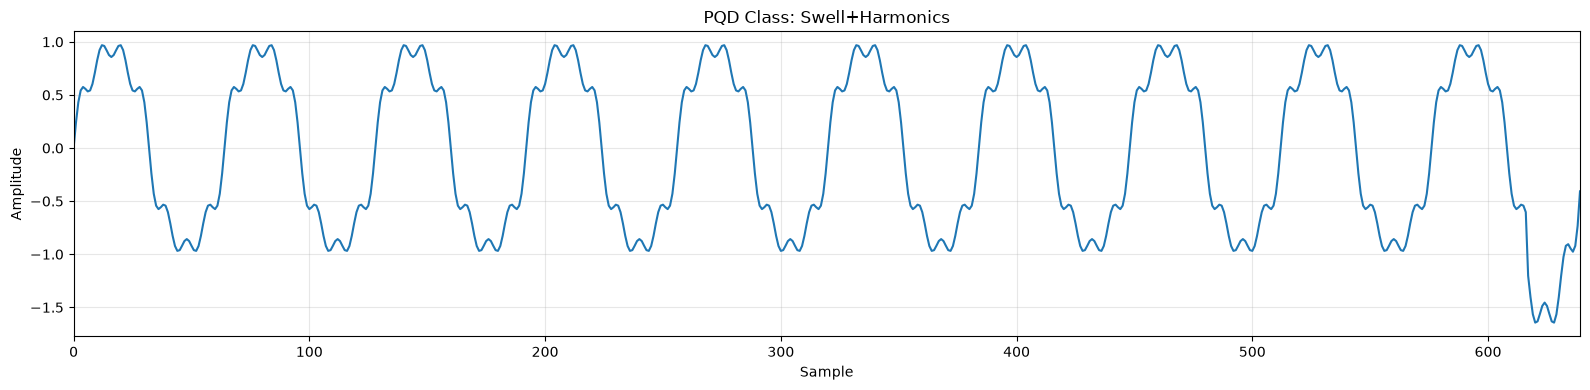

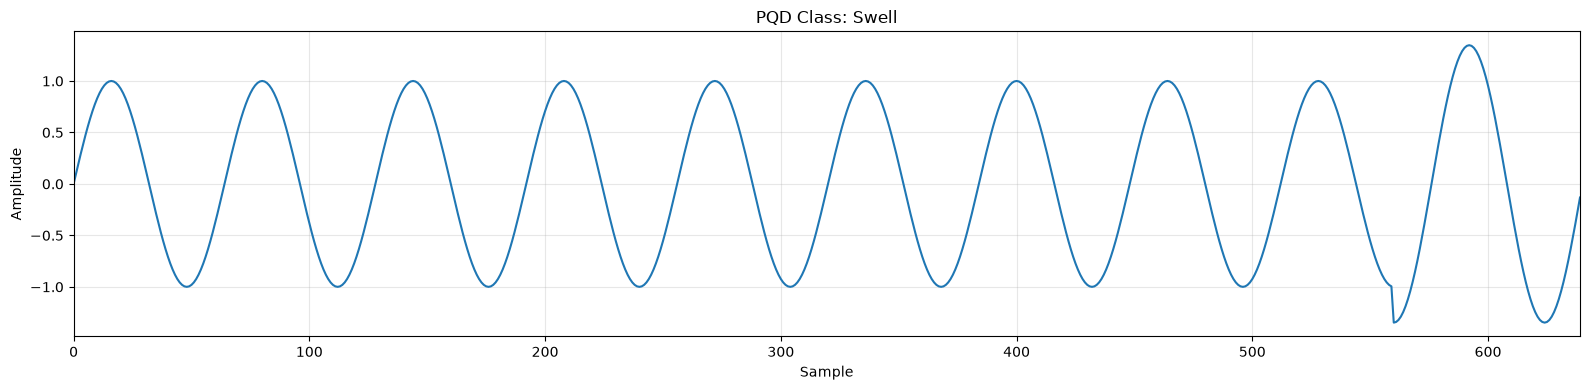

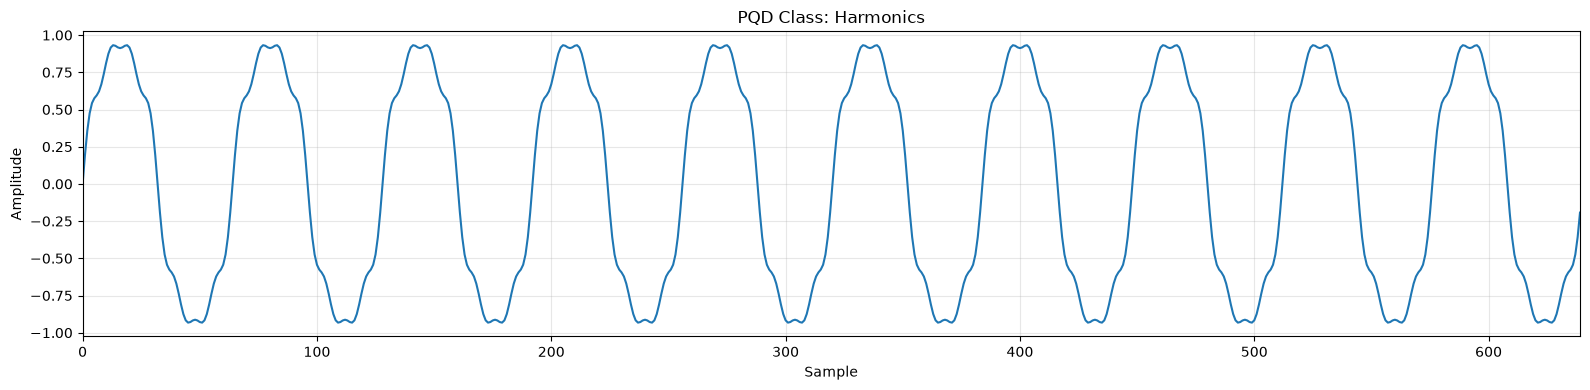

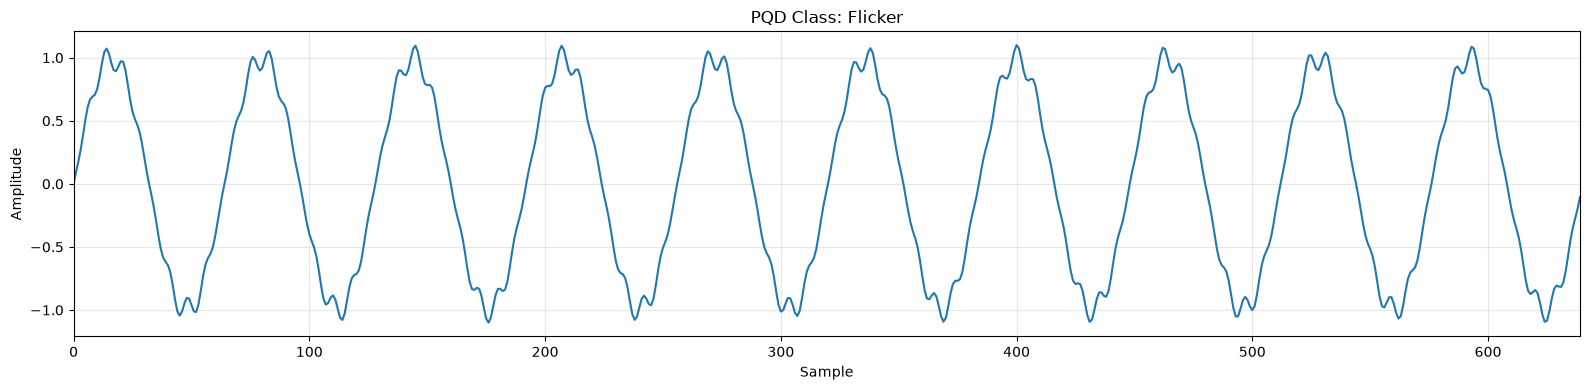

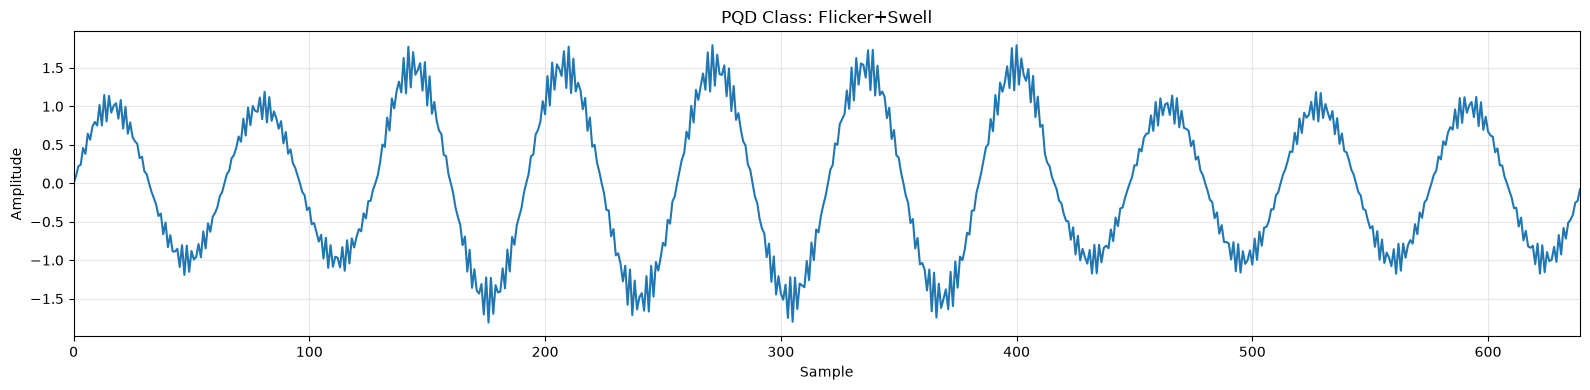

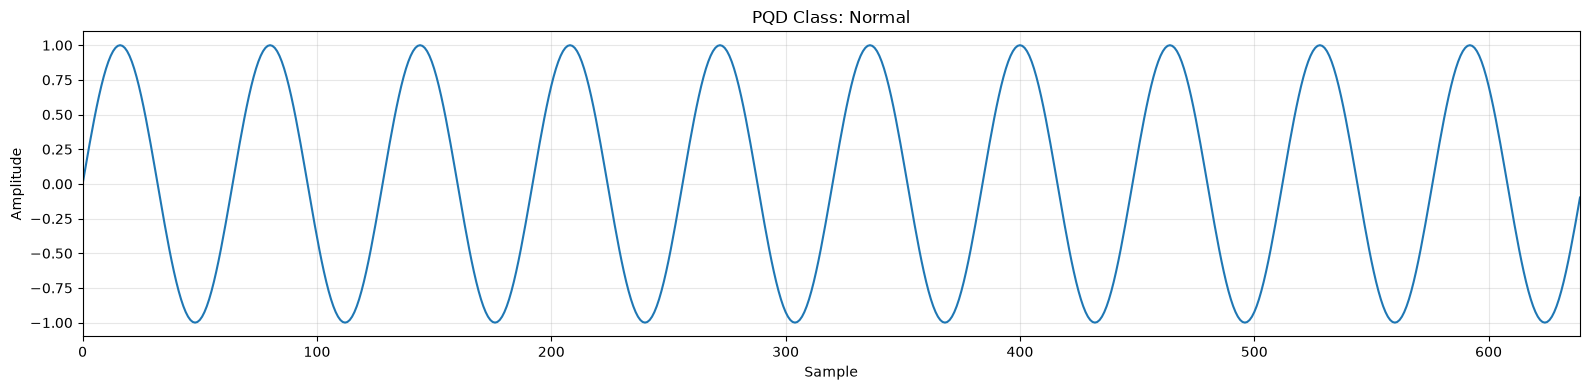

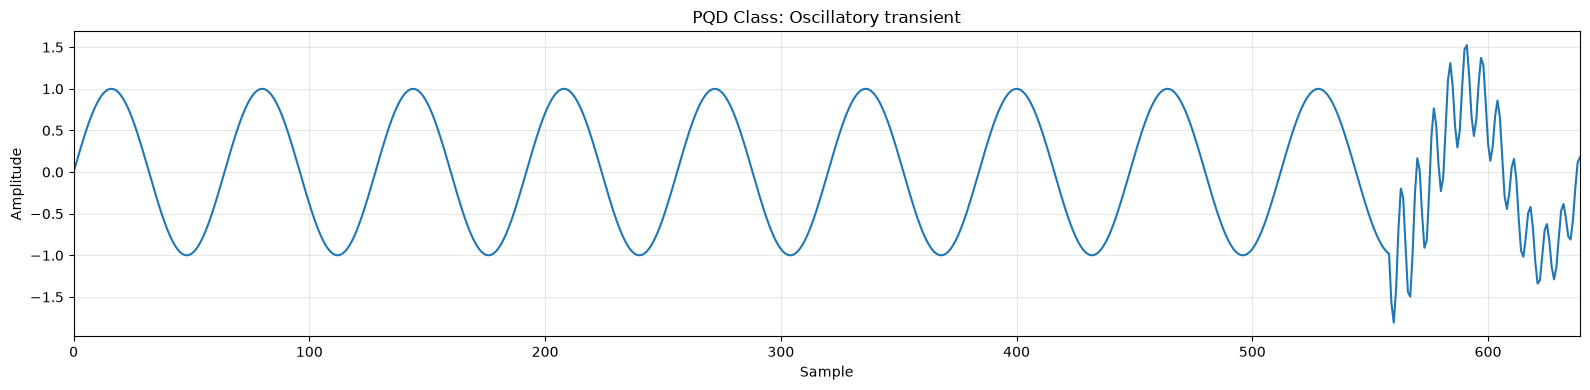

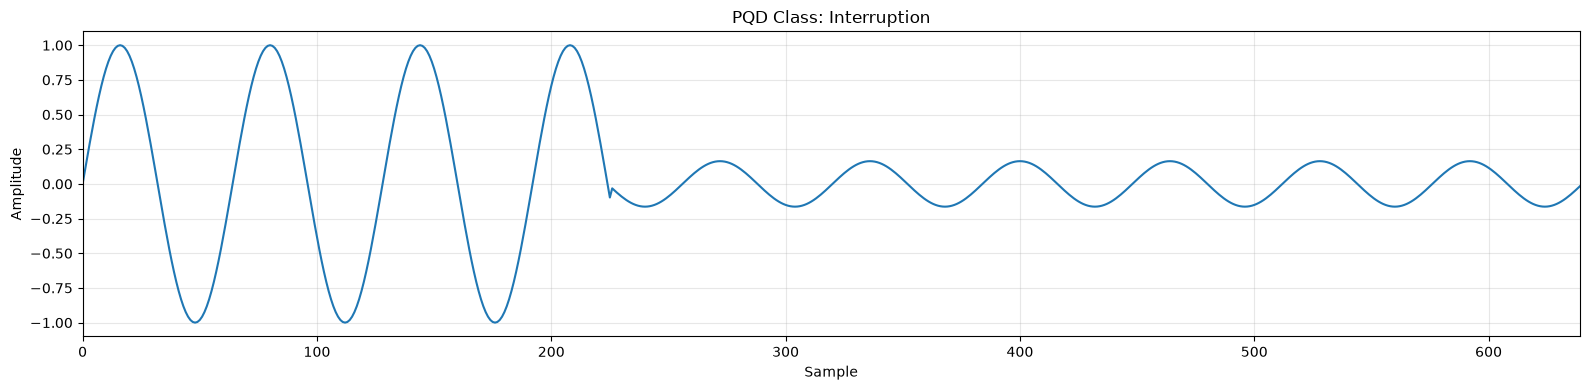

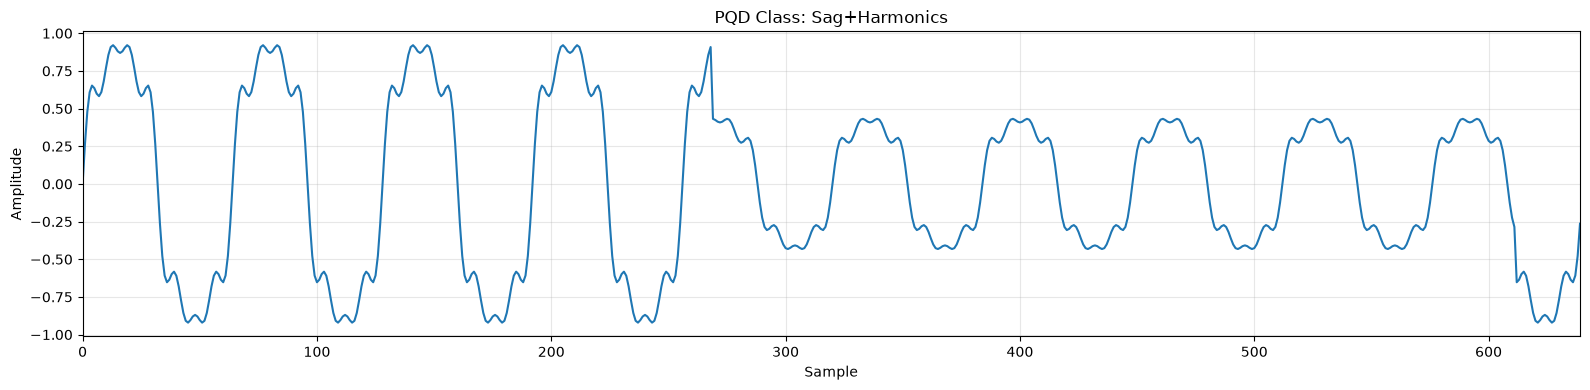

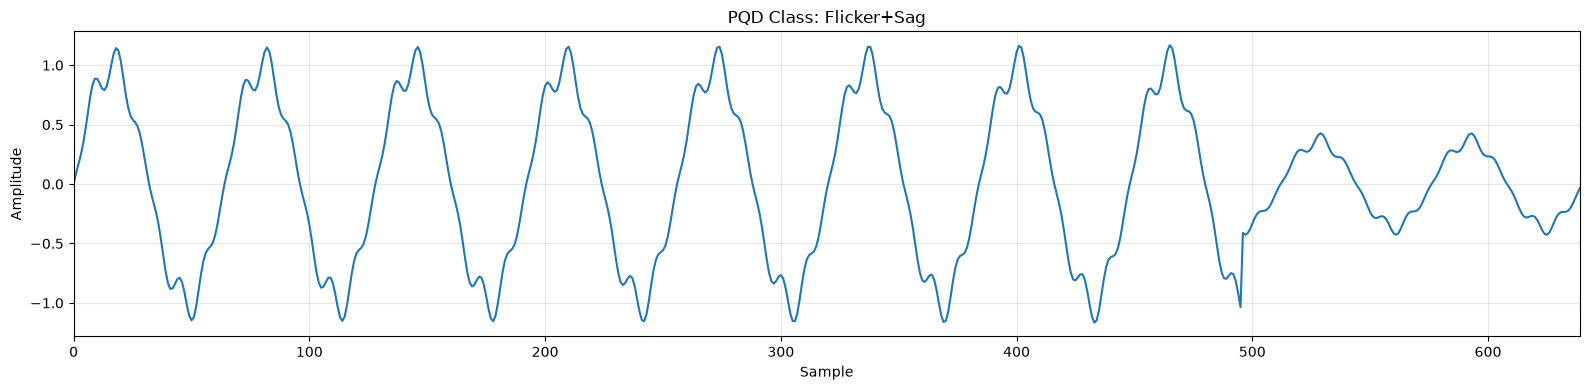

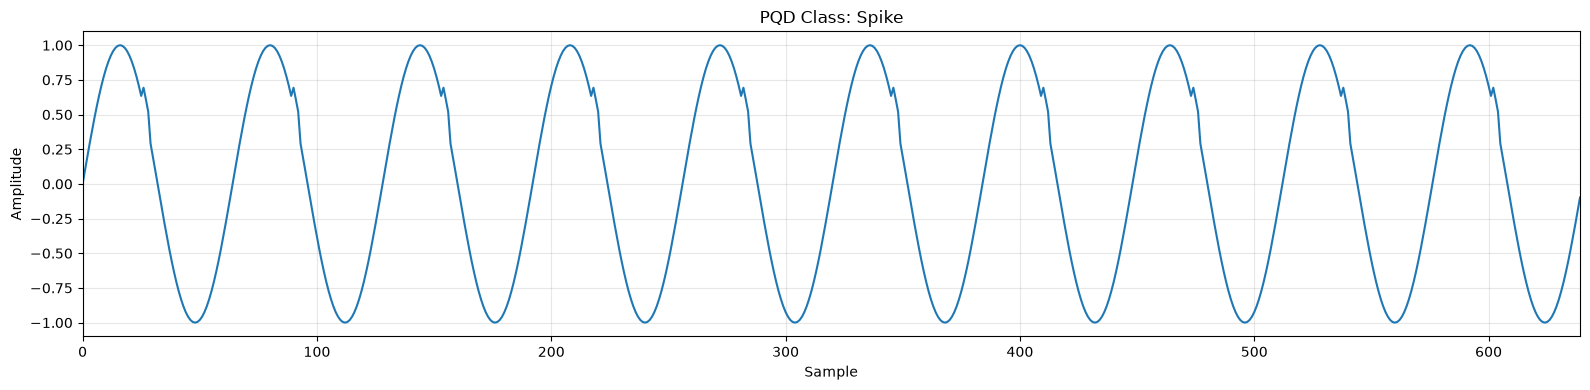

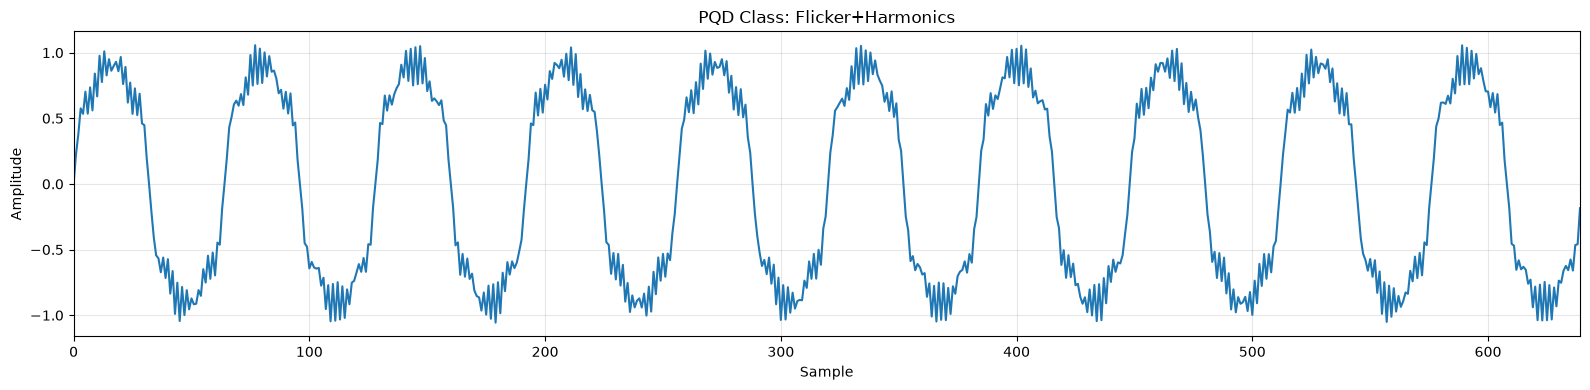

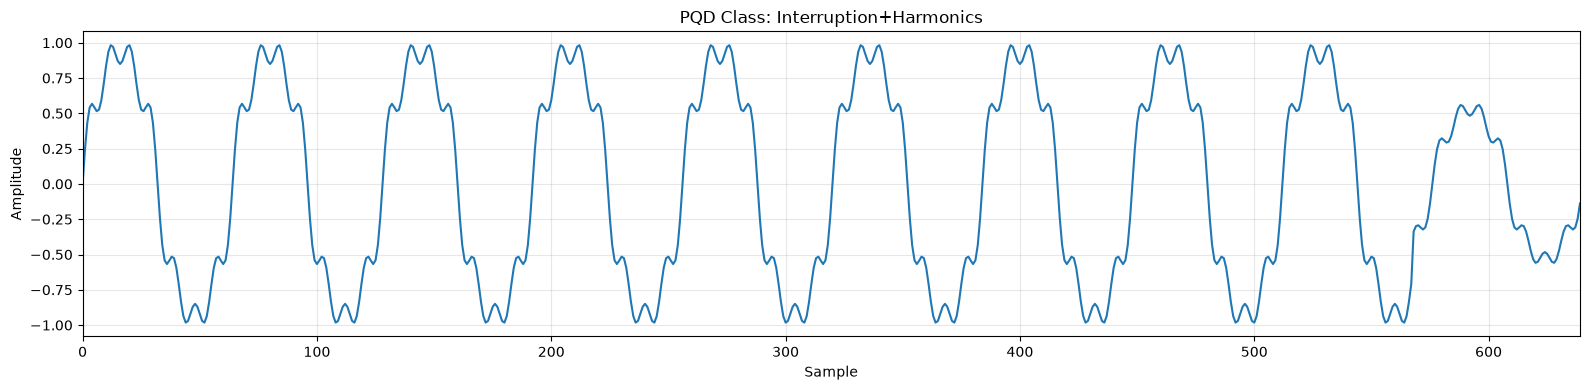

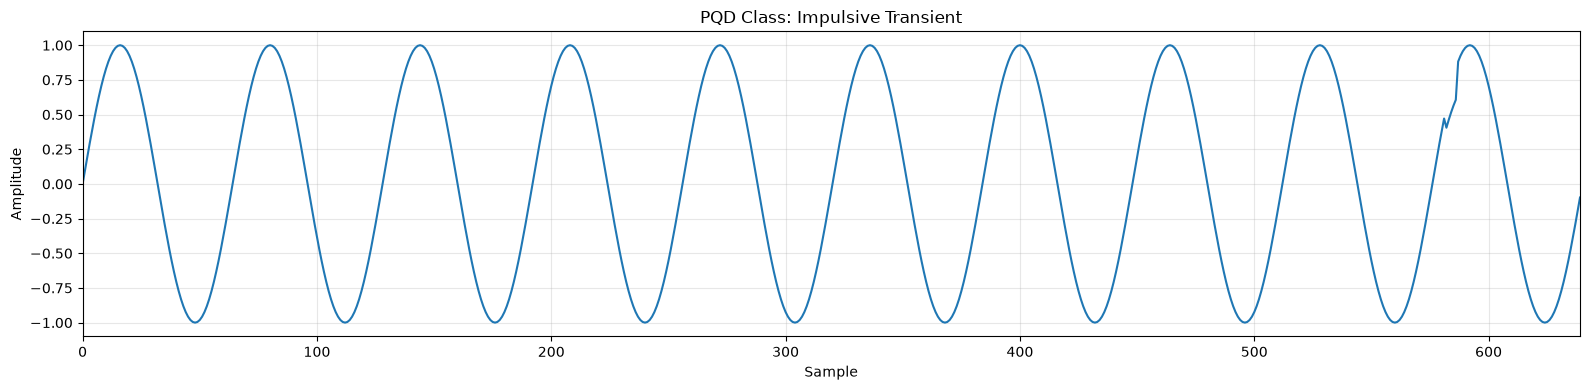

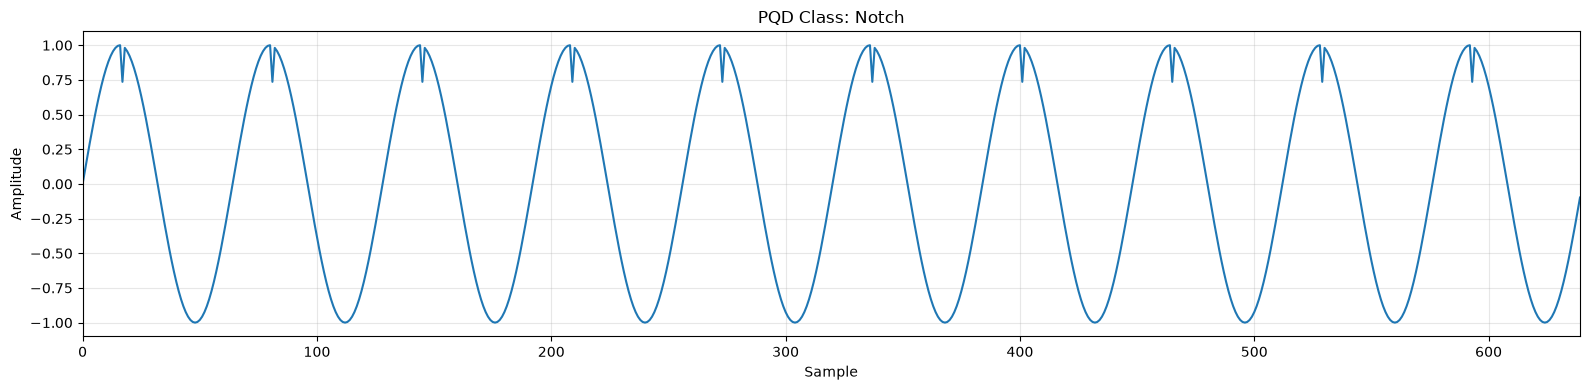

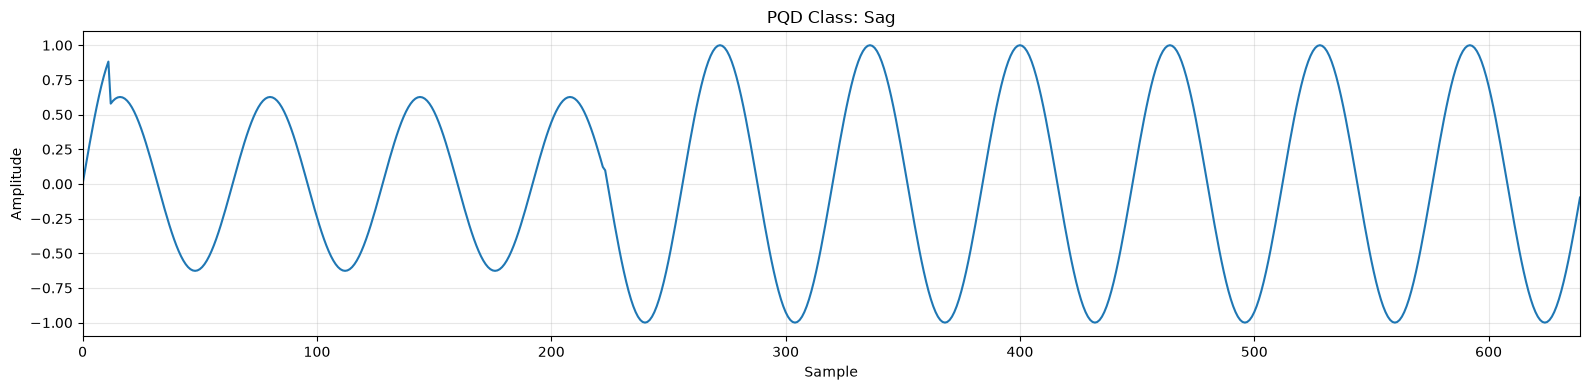

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# Configuration
# --------------------------------------------------

CSV_FILE = Path("../dataset/PQD-16c-Data/PQD-16C-Data.csv")

# --------------------------------------------------
# Load dataset
# --------------------------------------------------

df = pd.read_csv(CSV_FILE)

label_column = df.columns[0]
signal_columns = df.columns[1:]

# --------------------------------------------------
# Plot one random waveform from each class
# --------------------------------------------------

for label in df[label_column].unique():

    # Get all samples belonging to this class
    class_samples = df[df[label_column] == label]

    # Select one random waveform
    row = class_samples.sample(n=1).iloc[0]

    # Extract the 640 signal samples
    signal = row[signal_columns].astype(float).values

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    plt.figure(figsize=(16, 4))

    plt.plot(signal)

    plt.title(f"PQD Class: {label}")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude")
    plt.xlim(0, 639)

    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.show()

&nbsp;

# Split dataset into Train and Test

In [3]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split


# ============================================================
# CONFIGURATION
# ============================================================

CSV_FILE = Path("../dataset/PQD-16c-Data/PQD-16C-Data.csv")

RANDOM_STATE = 42

TRAIN_SIZE = 1024
VAL_SIZE = 256
TEST_SIZE = 320


# ============================================================
# LOAD ORIGINAL DATASET
# ============================================================

df = pd.read_csv(CSV_FILE)

print("=" * 60)
print("LOADING ORIGINAL DATASET")
print("=" * 60)

print("Original dataset:", df.shape)
print("First columns:", df.columns[:5].tolist())


# ============================================================
# FIRST COLUMN = LABEL
# REMAINING 640 COLUMNS = SIGNAL
# ============================================================

label_column = df.columns[0]
signal_columns = df.columns[1:]

y = df.iloc[:, 0].values
X = df.iloc[:, 1:].values


print()
print("X:", X.shape)
print("y:", y.shape)


# ============================================================
# VERIFY DATASET
# ============================================================

assert len(X) == len(y)

assert X.shape[1] == 640

assert (
    TRAIN_SIZE + VAL_SIZE + TEST_SIZE
    == len(X)
)


# ============================================================
# FIRST SPLIT
#
# 1024 TRAIN
# 576 TEMPORARY
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(

    X,
    y,

    train_size=TRAIN_SIZE,

    random_state=RANDOM_STATE,

    shuffle=True,

    stratify=y
)


# ============================================================
# SECOND SPLIT
#
# 256 VALIDATION
# 320 TEST
# ============================================================

X_val, X_test, y_val, y_test = train_test_split(

    X_temp,
    y_temp,

    train_size=VAL_SIZE,
    test_size=TEST_SIZE,

    random_state=RANDOM_STATE,

    shuffle=True,

    stratify=y_temp
)


# ============================================================
# CHECK FINAL SPLIT
# ============================================================

print()
print("=" * 60)
print("FINAL RANDOM SPLIT")
print("=" * 60)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print()

print("y_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)


# ============================================================
# CLASS DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

print("\nTrain:")
print(
    pd.Series(y_train)
    .value_counts()
    .sort_index()
)

print("\nValidation:")
print(
    pd.Series(y_val)
    .value_counts()
    .sort_index()
)

print("\nTest:")
print(
    pd.Series(y_test)
    .value_counts()
    .sort_index()
)


# ============================================================
# CREATE DATAFRAMES
#
# PRESERVE ORIGINAL FORMAT:
#
# FIRST COLUMN = LABEL
# NEXT 640 COLUMNS = SIGNAL
# ============================================================

def create_dataframe(X_data, y_data):

    result = pd.DataFrame(
        X_data,
        columns=signal_columns
    )

    result.insert(
        0,
        label_column,
        y_data
    )

    return result


train_df = create_dataframe(
    X_train,
    y_train
)

val_df = create_dataframe(
    X_val,
    y_val
)

test_df = create_dataframe(
    X_test,
    y_test
)


# ============================================================
# SAVE
# ============================================================

TRAIN_CSV = CSV_FILE.parent / "train.csv"
VAL_CSV = CSV_FILE.parent / "validation.csv"
TEST_CSV = CSV_FILE.parent / "test.csv"


train_df.to_csv(
    TRAIN_CSV,
    index=False
)

val_df.to_csv(
    VAL_CSV,
    index=False
)

test_df.to_csv(
    TEST_CSV,
    index=False
)


# ============================================================
# VERIFY SAVED DATA
# ============================================================

print()
print("=" * 60)
print("SAVED")
print("=" * 60)

print("Train:", TRAIN_CSV.resolve())
print("Validation:", VAL_CSV.resolve())
print("Test:", TEST_CSV.resolve())

print()

print("Train CSV:", train_df.shape)
print("Validation CSV:", val_df.shape)
print("Test CSV:", test_df.shape)

print()

print("First 5 columns:")
print(train_df.columns[:5].tolist())

LOADING ORIGINAL DATASET
Original dataset: (1600, 641)
First columns: ['labels', 'signals_1', 'signals_2', 'signals_3', 'signals_4']

X: (1600, 640)
y: (1600,)

FINAL RANDOM SPLIT
X_train: (1024, 640)
X_val  : (256, 640)
X_test : (320, 640)

y_train: (1024,)
y_val  : (256,)
y_test : (320,)

CLASS DISTRIBUTION

Train:
Flicker                   64
Flicker+Harmonics         64
Flicker+Sag               64
Flicker+Swell             64
Harmonics                 64
Impulsive Transient       64
Interruption              64
Interruption+Harmonics    64
Normal                    64
Notch                     64
Oscillatory transient     64
Sag                       64
Sag+Harmonics             64
Spike                     64
Swell                     64
Swell+Harmonics           64
Name: count, dtype: int64

Validation:
Flicker                   16
Flicker+Harmonics         16
Flicker+Sag               16
Flicker+Swell             16
Harmonics                 16
Impulsive Transient       16
Inte